Please upload train.csv


Saving train.csv to train (1).csv

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Processed data:


,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,True,False,True
1,1,38.0,1,0,71.2833,False,False,False
2,3,26.0,0,0,7.9250,False,False,True
3,1,35.0,1,0,53.1000,False,False,True
4,3,35.0,0,0,8.0500,True,False,True



Features used by the model:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']

Training samples: 712
Testing samples: 179

LOGISTIC REGRESSION TRAINED

Model Accuracy:
80.45 %

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


Confusion Matrix:
[[98 12]
 [23 46]]


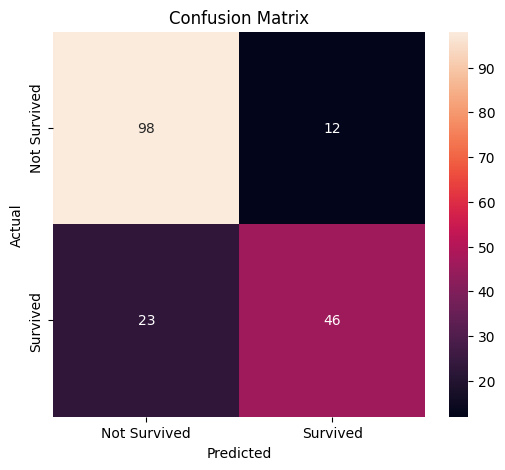


ROC-AUC Score:
0.8433


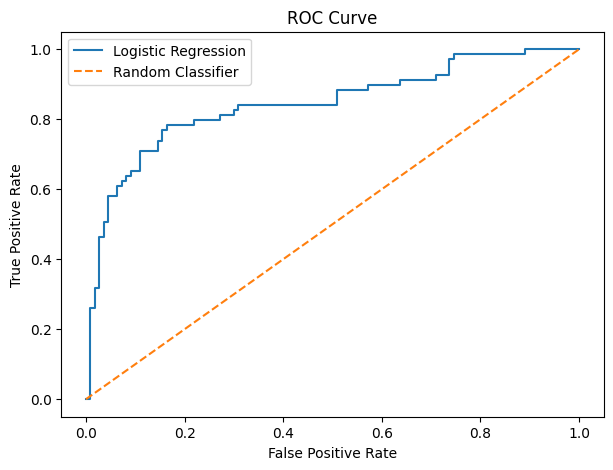


Logistic Regression Coefficients:


,Feature,Coefficient
4,Fare,0.099599
6,Embarked_Q,0.080683
3,Parch,-0.067158
7,Embarked_S,-0.171784
2,SibSp,-0.262672
1,Age,-0.502878
0,Pclass,-0.928698
5,Sex_male,-1.269598



STARTING REAL-TIME PREDICTION UI
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a01db1c96ab8af7ef6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================================
# TITANIC SURVIVAL PREDICTION
# LOGISTIC REGRESSION + REAL-TIME GRADIO UI
# ============================================================


# ============================================================
# 1. INSTALL GRADIO
# ============================================================

!pip install -q gradio


# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)


# ============================================================
# 3. UPLOAD train.csv
# ============================================================

print("Please upload train.csv")

uploaded = files.upload()

filename = list(uploaded.keys())[0]

data = pd.read_csv(filename)

print("\nDataset loaded successfully!")
print("Dataset shape:", data.shape)

display(data.head())


# ============================================================
# 4. CHECK DATASET
# ============================================================

print("\nDataset columns:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isnull().sum())


# ============================================================
# 5. SELECT INPUT FEATURES
# ============================================================

features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = data[features].copy()

y = data["Survived"].copy()


# ============================================================
# 6. HANDLE MISSING VALUES
# ============================================================

X["Age"] = X["Age"].fillna(
    X["Age"].median()
)

X["Embarked"] = X["Embarked"].fillna(
    X["Embarked"].mode()[0]
)


# ============================================================
# 7. CONVERT TEXT VALUES TO NUMBERS
# ============================================================

X = pd.get_dummies(
    X,
    columns=["Sex", "Embarked"],
    drop_first=True
)

print("\nProcessed data:")
display(X.head())

print("\nFeatures used by the model:")
print(X.columns.tolist())


# ============================================================
# 8. SPLIT DATA
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 9. SCALE FEATURES
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


# ============================================================
# 10. TRAIN LOGISTIC REGRESSION
# ============================================================

model = LogisticRegression(
    max_iter=500
)

model.fit(
    X_train_scaled,
    y_train
)

print("\n======================================")
print("LOGISTIC REGRESSION TRAINED")
print("======================================")


# ============================================================
# 11. TEST THE MODEL
# ============================================================

y_pred = model.predict(
    X_test_scaled
)


# ============================================================
# 12. ACCURACY
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nModel Accuracy:")
print(
    round(accuracy * 100, 2),
    "%"
)


# ============================================================
# 13. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)


# ============================================================
# 14. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Not Survived",
        "Survived"
    ],
    yticklabels=[
        "Not Survived",
        "Survived"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


# ============================================================
# 15. ROC CURVE
# ============================================================

probability = model.predict_proba(
    X_test_scaled
)[:, 1]

auc = roc_auc_score(
    y_test,
    probability
)

print("\nROC-AUC Score:")
print(round(auc, 4))

fpr, tpr, thresholds = roc_curve(
    y_test,
    probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.show()


# ============================================================
# 16. FEATURE COEFFICIENTS
# ============================================================

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(
    "Coefficient",
    ascending=False
)

print("\nLogistic Regression Coefficients:")

display(coefficients)


# ============================================================
# 17. REAL-TIME PREDICTION FUNCTION
# ============================================================

def predict_survival(
    pclass,
    sex,
    age,
    sibsp,
    parch,
    fare,
    embarked
):

    # Convert Sex

    if sex == "Male":
        sex_male = 1
    else:
        sex_male = 0


    # Convert Embarked

    if embarked == "Q":

        embarked_q = 1
        embarked_s = 0

    elif embarked == "S":

        embarked_q = 0
        embarked_s = 1

    else:

        embarked_q = 0
        embarked_s = 0


    # Create new passenger

    passenger = pd.DataFrame({

        "Pclass": [pclass],

        "Age": [age],

        "SibSp": [sibsp],

        "Parch": [parch],

        "Fare": [fare],

        "Sex_male": [sex_male],

        "Embarked_Q": [embarked_q],

        "Embarked_S": [embarked_s]

    })


    # Keep same column order

    passenger = passenger[X.columns]


    # Scale input

    passenger_scaled = scaler.transform(
        passenger
    )


    # Make prediction

    prediction = model.predict(
        passenger_scaled
    )[0]


    # Get probability

    probability = model.predict_proba(
        passenger_scaled
    )[0][1]


    # Result

    if prediction == 1:

        result = "SURVIVED"

    else:

        result = "NOT SURVIVED"


    return (
        result,
        f"{probability * 100:.2f}%"
    )


# ============================================================
# 18. CREATE GRADIO UI
# ============================================================

interface = gr.Interface(

    fn=predict_survival,

    inputs=[

        gr.Dropdown(
            choices=[1, 2, 3],
            value=3,
            label="Passenger Class"
        ),

        gr.Radio(
            choices=["Male", "Female"],
            value="Female",
            label="Sex"
        ),

        gr.Number(
            value=25,
            label="Age"
        ),

        gr.Number(
            value=0,
            label="Siblings / Spouses"
        ),

        gr.Number(
            value=0,
            label="Parents / Children"
        ),

        gr.Number(
            value=30,
            label="Fare"
        ),

        gr.Radio(
            choices=["S", "C", "Q"],
            value="S",
            label="Port of Embarkation"
        )

    ],

    outputs=[

        gr.Textbox(
            label="Prediction"
        ),

        gr.Textbox(
            label="Survival Probability"
        )

    ],

    title="Titanic Survival Prediction",

    description=(
        "Logistic Regression based "
        "real-time Titanic survival prediction"
    )

)


# ============================================================
# 19. LAUNCH UI
# ============================================================

print("\n======================================")
print("STARTING REAL-TIME PREDICTION UI")
print("======================================")

interface.launch(
    share=True
)